# INF-GRAM — Final project: vertebral-column classification

**Goal.** Predict whether a patient's vertebral column is **abnormal** from six biomechanical measurements.

**Target coding (used throughout the notebook):**

| Code | Meaning | Original classes |
|---|---|---|
| `0` | **Normal** | NO |
| `1` | **Abnormal** | DH (Disk Hernia) or SL (Spondylolisthesis) |

The **positive class is 1 = Abnormal**. Sensitivity therefore means "proportion of abnormal patients detected",
and specificity means "proportion of normal patients correctly classified as normal".

**Methodological rule.** One stratified train/test split is made early (Task 3). Every later choice
(scaling, hyperparameters, model selection, threshold choice) uses the **training set only**, through
cross-validation. The test set is used once, in Task 6, after all choices are fixed.

## 0. Setup

In [283]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

SEED = 42
DATA = Path(".")

## Task 1 — Import and data audit

The file is whitespace-separated with a header line. Six numeric predictors, one text label `class` (DH / SL / NO).

In [101]:
# Load the dataset. Based on typical formats of this dataset, it is space-separated.
df = pd.read_csv(DATA / "column_3C.txt", sep="\s+")

# Document and display structure
print("--- Dataset Shape ---")
print(df.shape)

print("--- Missing Values ---")
print(df.isna().sum())

print("--- Duplicate Rows ---")
print(df.duplicated().sum())

print("--- Dataset Info ---")
print(df.info())

print("--- Class Distribution ---")
print(df[df.columns].value_counts())

print("--- First 5 Rows ---")
df.head()

print("--- Original 3-class counts ---")
df["class"].value_counts().to_frame("count")

--- Dataset Shape ---
(310, 7)
--- Missing Values ---
pelvic_incidence            0
pelvic_tilt                 0
lumbar_lordosis_angle       0
sacral_slope                0
pelvic_radius               0
degree_spondylolisthesis    0
class                       0
dtype: int64
--- Duplicate Rows ---
0
--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 310 entries, 0 to 309
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   pelvic_incidence          310 non-null    float64
 1   pelvic_tilt               310 non-null    float64
 2   lumbar_lordosis_angle     310 non-null    float64
 3   sacral_slope              310 non-null    float64
 4   pelvic_radius             310 non-null    float64
 5   degree_spondylolisthesis  310 non-null    float64
 6   class                     310 non-null    object 
dtypes: float64(6), object(1)
memory usage: 17.1+ KB
None
--- Class Distributi

<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_6641/879887638.py:2: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv(DATA / "column_3C.txt", sep="\s+")


,count
class,
SL,150
NO,100
DH,60


### Binary target

`0 = Normal (NO)`, `1 = Abnormal (DH or SL)`. An explicit mapping is used (rather than "anything that isn't NO")
so that an unexpected label would raise an error instead of being silently classified.

In [104]:
df['target'] = df['class'].apply(lambda x: 0 if x == 'NO' else 1)

# Check the mapping row by row
pd.crosstab(df["class"], df["target"])

target,0,1
class,,
DH,0,60
NO,100,0
SL,0,150


,count,proportion
target,,
Normal (0),100,0.32
Abnormal (1),210,0.68


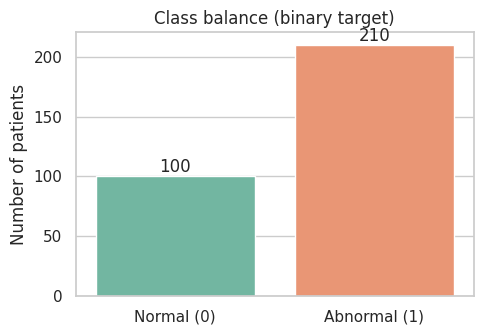

In [161]:
TARGET_NAME = {0: "Normal (0)", 1: "Abnormal (1)"}
ORDER = list(TARGET_NAME.values())

balance = (
    df["target"].value_counts().sort_index()
    .rename(index=TARGET_NAME).to_frame("count")
)
balance["proportion"] = np.round(balance["count"] / balance["count"].sum(), 2)
display(balance)

x = df.target.map(TARGET_NAME)
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(df, x=x, order=ORDER, palette='Set2', hue='target', legend=False, ax=ax)
for c in ax.containers:
    ax.bar_label(c)

ax.set(xlabel="", ylabel="Number of patients", title="Class balance (binary target)")
plt.tight_layout()
plt.show()

In [138]:
FEATURES = df.columns[:-2]

X = df[FEATURES]
y = df["target"]

print("X:", X.shape, " y:", y.shape)

X: (310, 6)  y: (310,)


### Audit summary

- **310 patients, 6 numeric predictors (float64) and 1 label.** No missing values and no duplicated rows, so no
  imputation is needed.
- Original classes: **SL = 150, NO = 100, DH = 60**.
- Binary target: **Normal (0) = 100 (32.3%)**, **Abnormal (1) = 210 (67.7%)**. The classes are imbalanced about 2:1
  *in favour of the abnormal class*. This prevalence comes from how the dataset was built (hospital cases), not from
  the general population. A trivial "always abnormal" classifier would already reach 67.7% accuracy, which is why
  accuracy is not used to select models.

## Task 2 — Descriptive analysis

> Note: this descriptive analysis is done on the full dataset, *before* the split. That is acceptable because it
> only informs understanding of the data; no statistic computed here is fed into a model. All preprocessing that
> the models use (scaling) is learned inside pipelines on training folds only.

In [141]:
print("--- Overall summary ---")
display(df.describe().T)

--- Overall summary ---


,count,mean,std,min,25%,50%,75%,max
pelvic_incidence,310.0,60.496484,17.236109,26.15,46.4325,58.690,72.8800,129.83
pelvic_tilt,310.0,17.542903,10.008140,-6.55,10.6675,16.360,22.1200,49.43
lumbar_lordosis_angle,310.0,51.930710,18.553766,14.00,37.0000,49.565,63.0000,125.74
sacral_slope,310.0,42.953871,13.422748,13.37,33.3475,42.405,52.6925,121.43
pelvic_radius,310.0,117.920548,13.317629,70.08,110.7100,118.265,125.4675,163.07
degree_spondylolisthesis,310.0,26.296742,37.558883,-11.06,1.6000,11.765,41.2850,418.54
target,310.0,0.677419,0.468220,0.00,0.0000,1.000,1.0000,1.00


In [147]:
by_class = pd.concat(
    {TARGET_NAME[k]: describe(X[y == k]) for k, describe in [
        (0, lambda X: X.describe().T),
        (1, lambda X: X.describe().T),
    ]},
    axis=1
)
by_class

Normal (0)                                         \
                              count      mean        std     min       25%   
pelvic_incidence              100.0   51.6856  12.367900   30.74   42.8200   
pelvic_tilt                   100.0   12.8218   6.778658   -5.85    8.8025   
lumbar_lordosis_angle         100.0   43.5423  12.361581   19.07   35.0000   
sacral_slope                  100.0   38.8638   9.623776   17.39   32.3425   
pelvic_radius                 100.0  123.8912   9.013755  100.50  118.1800   
degree_spondylolisthesis      100.0    2.1870   6.307020  -11.06   -1.5100   

                                                    Abnormal (1)              \
                              50%       75%     max        count        mean   
pelvic_incidence           50.125   61.4725   89.83        210.0   64.692143   
pelvic_tilt                13.485   16.7875   29.89        210.0   19.791048   
lumbar_lordosis_angle      42.640   51.6025   90.56        210.0   55.925190   
sacral_slope               37.060   44.6050   67.20        210.0   44.901524   
pelvic_radius             123.875  129.0400  147.89        210.0  115.077381   
degree_spondylolisthesis    1.155    4.9675   31.17        210.0   37.777571   

                                                                         \
                                std    min       25%      50%       75%   
pelvic_incidence          17.661807  26.15   50.1050   65.275   77.5975   
pelvic_tilt               10.515653  -6.55   13.0475   18.795   24.8125   
lumbar_lordosis_angle     19.668972  14.00   41.1175   56.150   68.1050   
sacral_slope              14.515133  13.37   34.3800   44.640   55.1425   
pelvic_radius             14.090965  70.08  107.3075  115.650  123.1350   
degree_spondylolisthesis  40.696738 -10.68    7.2600   31.945   55.3750   

                                  
                             max  
pelvic_incidence          129.83  
pelvic_tilt                49.43  
lumbar_lordosis_angle     125.74  
sacral_slope              121.43  
pelvic_radius             163.07  
degree_spondylolisthesis  418.54

In [180]:
long = df.assign(group=x).melt(id_vars="group", value_vars=FEATURES, var_name="feature", value_name="value")

long.head()

,group,feature,value
0,Abnormal (1),pelvic_incidence,63.03
1,Abnormal (1),pelvic_incidence,39.06
2,Abnormal (1),pelvic_incidence,68.83
3,Abnormal (1),pelvic_incidence,69.30
4,Abnormal (1),pelvic_incidence,49.71


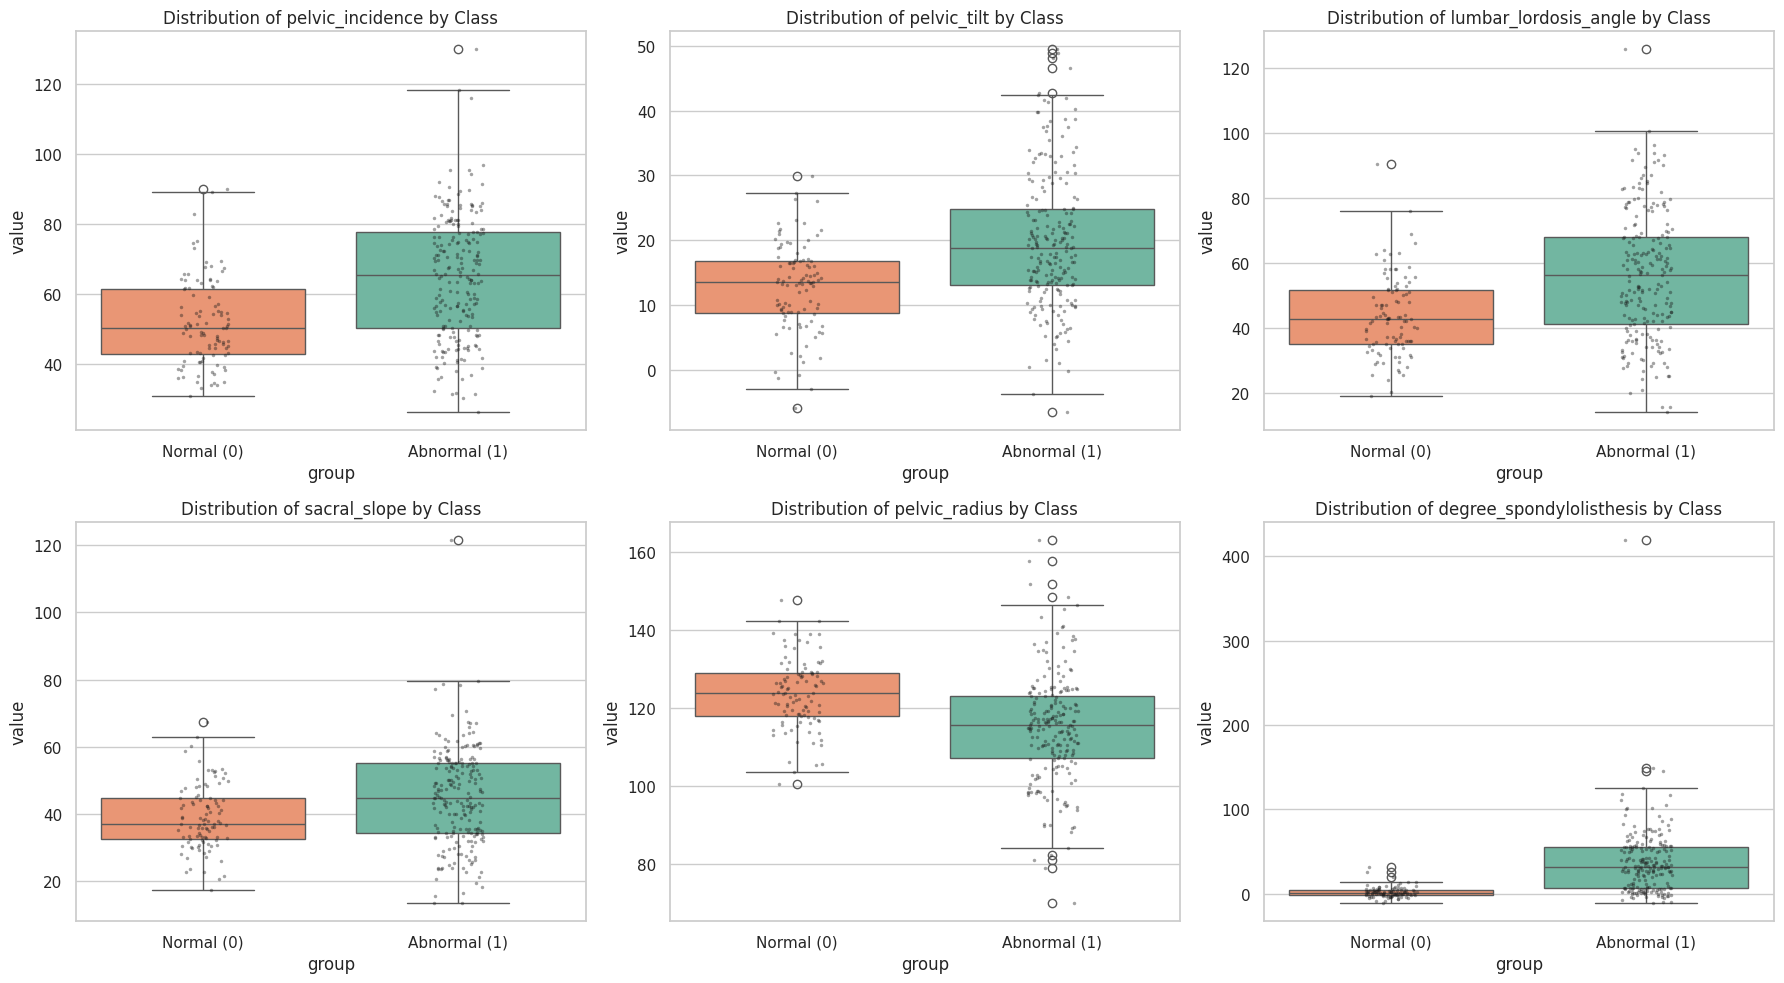

In [182]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, feat in zip(axes.ravel(), FEATURES):
    sub = long[long.feature == feat]
    sns.boxplot(data=sub, x='group', y='value', ax=ax, palette='Set2', order=ORDER, hue='group')
    sns.stripplot(data=sub, x="group", y="value", ax=ax, order=ORDER, color="k", size=2.5, alpha=0.4)
    ax.set_title(f'Distribution of {feat} by Class')

plt.tight_layout()
plt.show()

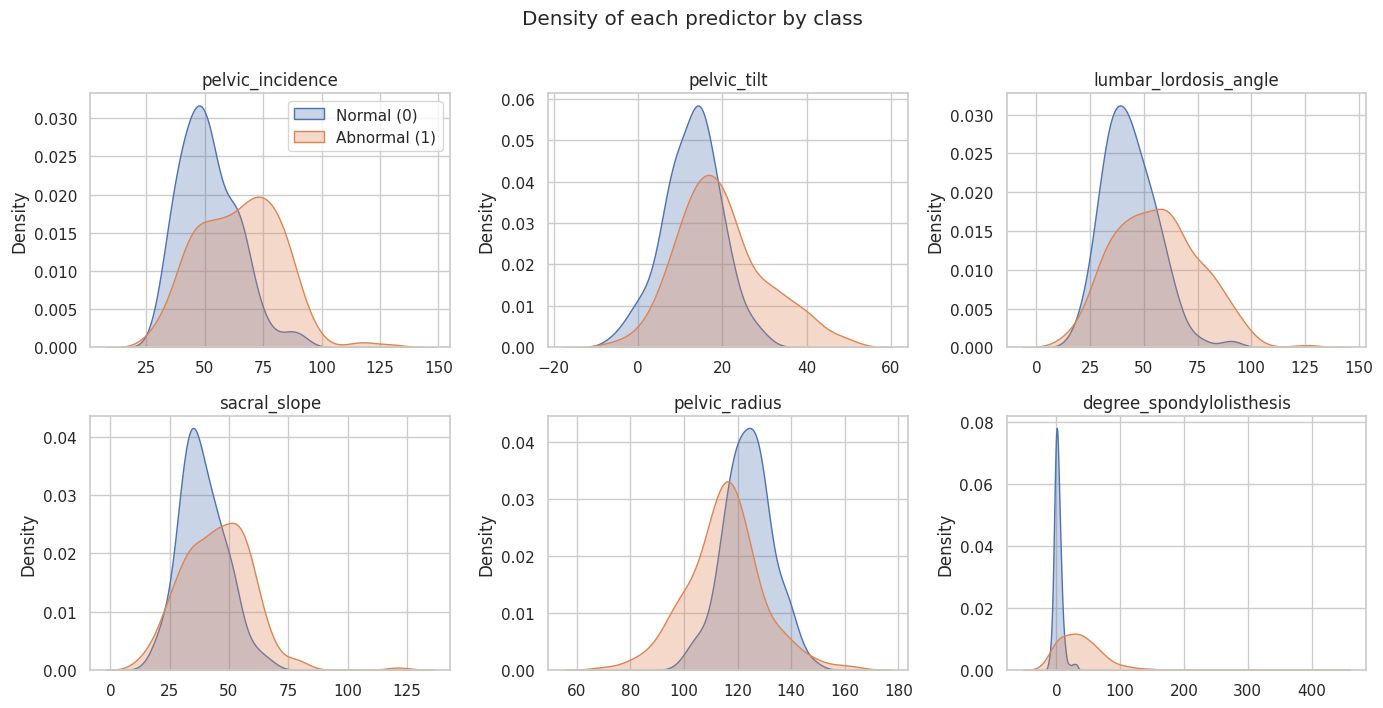

In [191]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, feat in zip(axes.ravel(), FEATURES):
  for k in TARGET_NAME.keys():
    val = X.loc[y == k, feat]
    sns.kdeplot(val, fill=True, alpha=0.3, label=TARGET_NAME[k], ax=ax)
    ax.set(title=feat, xlabel="")
axes[0, 0].legend()

fig.suptitle("Density of each predictor by class", y=1.01)
plt.tight_layout()
plt.show()

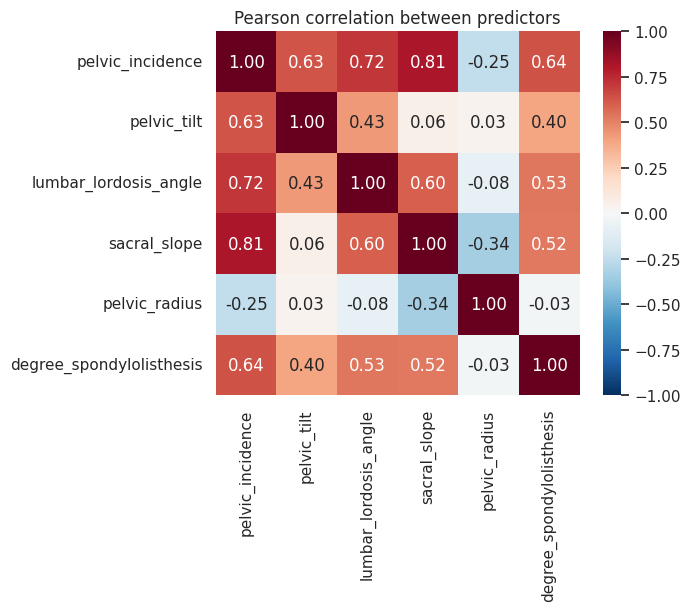

In [209]:
corr = X.corr()
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax)

ax.set_title("Pearson correlation between predictors")
plt.tight_layout()
plt.show()

The strong correlations involving `pelvic_incidence` suggest a structural relationship. In spinal biomechanics,
**pelvic incidence = pelvic tilt + sacral slope** by geometric definition. Let us check it on the data:

In [210]:
residual = X["pelvic_incidence"] - (X["pelvic_tilt"] + X["sacral_slope"])
print(residual.describe())
print("\nShare of patients where |PI - (PT + SS)| < 0.05:", (residual.abs() < 0.05).mean().round(3))

count    310.000000
mean      -0.000290
std        0.005359
min       -0.010000
25%        0.000000
50%        0.000000
75%        0.000000
max        0.010000
dtype: float64

Share of patients where |PI - (PT + SS)| < 0.05: 1.0


In [211]:
# Extreme value of degree_spondylolisthesis
X.sort_values("degree_spondylolisthesis", ascending=False).head(3).join(df["class"])

,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis,class
115,129.83,8.40,48.38,121.43,107.69,418.54,SL
95,57.52,33.65,50.91,23.88,140.98,148.75,SL
75,70.22,39.82,68.12,30.40,148.53,145.38,SL


### Notable relationships and differences

1. **`degree_spondylolisthesis` is by far the most discriminating variable.** Normal patients have a median of
   1.2 (IQR 6.5), centred around 0. Abnormal patients have a median of 31.9 (IQR 48.1), and their distribution is
   strongly right-skewed. The two boxplots barely overlap. Clinically this makes sense, since the variable measures
   the forward slip of a vertebra, which is the defining feature of spondylolisthesis.

2. **`pelvic_radius` is *lower* in abnormal patients** (median 115.7 vs 123.9). It is the only predictor whose values
   decrease in the abnormal class. It is also almost uncorrelated with the other predictors (|r| ≤ 0.34), so it
   carries information the other predictors do not.

3. **Exact structural redundancy: pelvic incidence = pelvic tilt + sacral slope.** The identity holds for
   **every** patient up to rounding (residual within ±0.01). This explains the high correlations PI–SS (0.81) and
   PI–PT (0.63). One of the three variables is completely redundant, so the predictors are perfectly collinear.
   This does not harm prediction, but **the individual coefficients of PI, PT and SS in a linear model cannot be
   interpreted separately**. L2 regularisation in logistic regression keeps the fit stable despite this.

4. **The abnormal class is more variable than the normal class** for all six predictors (larger standard
   deviation and IQR). This is expected, because "Abnormal" merges two different conditions (DH and SL).
   Most of the very high slip values come from SL patients.

5. **Data-quality concern.** Patient #115 (SL) has `degree_spondylolisthesis` = 418.5 and `sacral_slope` = 121.4°.
   Both values are far outside the rest of the data, and a sacral slope above 90° is anatomically implausible. This
   is probably a recording error. We **keep** the patient, because no rule for removing records was set in advance
   and we have no way to check the original record. This choice is defensible: random forests split on rank order,
   so they are robust to it, and the patient is clearly abnormal for every model. It is listed as a limitation.

## Task 3 — Development / test split

One stratified 80 / 20 split with `random_state=SEED`. From here on, `X_test` / `y_test` are **not used** until Task 6.

In [219]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

split_table = pd.DataFrame({
    "n": [len(y), len(y_train), len(y_test)],
    "n Normal (0)": [len(y == 0), len(y_train == 0), len(y_test == 0)],
    "n Abnormal (1)": [len(y == 1), len(y_train == 1), len(y_test == 1)],
    "proportion Abnormal": [y.mean(), y_train.mean(), y_test.mean()],
}, index=["full", "train", "test"])
split_table

,n,n Normal (0),n Abnormal (1),proportion Abnormal
full,310,310,310,0.677419
train,248,248,248,0.677419
test,62,62,62,0.677419


Stratification keeps the Abnormal proportion almost identical in the three sets. The test set holds only
62 patients, so each misclassified test patient changes a test metric by about 1.6 percentage points (or more for
class-specific metrics: there are only 20 Normal patients in the test set, so one error changes specificity by 5 points).

### Cross-validation strategy (shared by all models)

- **5-fold stratified cross-validation** on the training set, shuffled with `SEED`. The same `cv` object is used for
  every model, so all models see exactly the same folds.
- **Primary selection metric: ROC AUC.** It is threshold-independent and measures how well a model *ranks*
  abnormal above normal patients. The class balance is about 2:1, which would make accuracy misleading, and the
  decision threshold is chosen separately in Task 7. Using ROC AUC to select the model keeps those two questions separate.
- Scaling is placed **inside** each `Pipeline`. During cross-validation the scaler is refit on the training folds
  only, so the validation fold never leaks into preprocessing.

In [273]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
REFIT = "roc_auc"
SCORING = {"roc_auc": "roc_auc", "accuracy": "accuracy", "recall": "recall",
           "precision": "precision", "f1": "f1"}

def cv_summary(search):
    # CV scores (mean ± std over the 5 folds) of the best configuration of a fitted GridSearchCV
    r = pd.DataFrame(search.cv_results_).iloc[search.best_index_]
    return pd.Series({m: f"{r[f'mean_test_{m}']:.3f} ± {r[f'std_test_{m}']:.3f}" for m in SCORING})

## Task 4 — Baseline: logistic regression

Pipeline: `StandardScaler` → `LogisticRegression`.

**Hyperparameter `C`** is the *inverse* of the L2 regularisation strength: small `C` means strong shrinkage of the
coefficients toward 0 (simpler model), large `C` means almost no penalty. Scaling matters here because the penalty
treats all coefficients equally, so features must be on comparable scales. We search `C` on a log grid from
1e-3 to 1e3.

In [295]:
lr_pipe = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, random_state=SEED),
)
lr_param = {
    "logisticregression__C": np.logspace(-3, 3, 13)
}

lr_search = GridSearchCV(lr_pipe, lr_param, scoring=SCORING, refit=REFIT, cv=cv)
lr_search.fit(X_train, y_train)

print("Best C:", lr_search.best_params_["logisticregression__C"].round(4))
cv_summary(lr_search).to_frame("LogReg CV (mean ± std)")

Best C: 3.1623


,LogReg CV (mean ± std)
roc_auc,0.925 ± 0.048
accuracy,0.851 ± 0.073
recall,0.887 ± 0.071
precision,0.894 ± 0.059
f1,0.889 ± 0.056


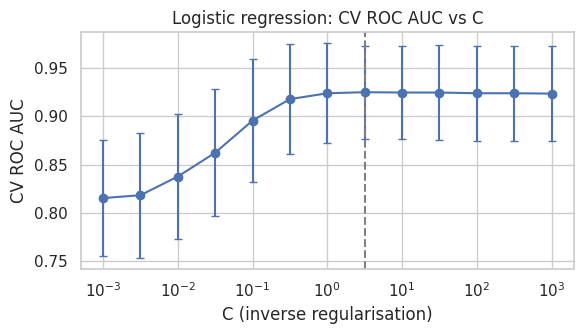

In [276]:
res = pd.DataFrame(search_lr.cv_results_)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.errorbar(res["param_logisticregression__C"].astype(float), res["mean_test_roc_auc"], yerr=res["std_test_roc_auc"],
            marker="o", capsize=3)
ax.axvline(search_lr.best_params_["logisticregression__C"], ls="--", c="grey")
ax.set(xscale="log", xlabel="C (inverse regularisation)", ylabel="CV ROC AUC",
       title="Logistic regression: CV ROC AUC vs C")
plt.tight_layout(); plt.show()

In [281]:
# Coefficients of the tuned model (on standardised features -> comparable magnitudes)
best_lr = search_lr.best_estimator_
coefs = pd.Series(best_lr.named_steps["logisticregression"].coef_[0], index=FEATURES).sort_values(key=abs, ascending=False)
coefs.to_frame("coefficient (per 1 SD)")

,coefficient (per 1 SD)
degree_spondylolisthesis,4.782123
pelvic_radius,-1.086042
pelvic_tilt,0.843464
sacral_slope,-0.758322
lumbar_lordosis_angle,-0.304277
pelvic_incidence,-0.109081


### Interpretation

- **Selected C ≈ 3.16. CV ROC AUC = 0.925 ± 0.048** (mean ± std over 5 folds). Accuracy is 0.851 and sensitivity
  is 0.887 at the default 0.5 threshold.
- The curve of CV AUC against C shows **strong regularisation (C ≤ 0.1) clearly hurts**. Above C ≈ 1 there is a
  plateau where the choice of C hardly matters. The data support a nearly unpenalised linear model.
- The standardised coefficients confirm the descriptive analysis. `degree_spondylolisthesis` dominates
  (+4.8 per SD), and `pelvic_radius` is negative (−1.1 per SD: a lower radius means a higher risk of being abnormal).
  As explained in Task 2, the coefficients of PI, PT and SS should not be interpreted individually because
  PI = PT + SS.

## Task 5 — Two additional model families

### 5a. Support Vector Machine with RBF kernel

**Why it is a reasonable candidate.**
- Logistic regression can only draw a linear boundary. An RBF-kernel SVM can learn a **non-linear** boundary, which
  could help if, for example, both very low and very high values of a measurement are abnormal.
- SVMs work well on **small, low-dimensional** tabular datasets (here 248 training patients, 6 features).
- The margin maximisation and the `C` penalty give built-in regularisation.

**Pipeline.** `StandardScaler` → `SVC(kernel="rbf")`. Scaling is essential because the RBF kernel uses Euclidean
distances. Without it, the features with the largest range (e.g. `degree_spondylolisthesis`) would dominate.
`probability=True` gives probabilities (Platt scaling, fitted by internal CV) for the later threshold analysis.

**Hyperparameters tuned.**
- `C`: penalty for margin violations (large = fits training data more closely, risk of overfitting).
- `gamma`: width of the RBF kernel (large = very local, wiggly boundary; small = smooth, almost linear boundary).

In [299]:
svm_pip = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", probability=True, random_state=SEED),
)

svm_grid = {
    "svc__C": np.logspace(-2, 5, 8),
    "svc__gamma": ["scale", 1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1.0],
}
svm_search = GridSearchCV(svm_pip, svm_grid, scoring=SCORING, refit=REFIT, cv=cv, n_jobs=-1)
svm_search.fit(X_train, y_train)

print("Best params:", svm_search.best_params_)
cv_summary(svm_search).to_frame("SVM CV (mean ± std)")

Best params: {'svc__C': np.float64(1000.0), 'svc__gamma': 0.001}


,SVM CV (mean ± std)
roc_auc,0.929 ± 0.042
accuracy,0.843 ± 0.053
recall,0.881 ± 0.045
precision,0.887 ± 0.045
f1,0.883 ± 0.040


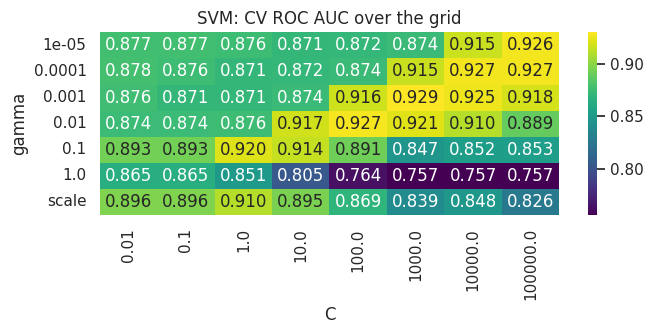

In [300]:
res = pd.DataFrame(svm_search.cv_results_)
heat = res.pivot_table(index="param_svc__gamma", columns="param_svc__C", values="mean_test_roc_auc", aggfunc="first")
heat.index = heat.index.astype(str)

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="viridis", ax=ax)

ax.set(title="SVM: CV ROC AUC over the grid", xlabel="C", ylabel="gamma")
plt.tight_layout()
plt.show()

### SVM result

- **Selected C = 1000, gamma = 0.001. CV ROC AUC = 0.929 ± 0.042.**
- A very small `gamma` means a very wide kernel, so the decision boundary is **smooth and close to linear**.
  The large `C` compensates for the weak flexibility of that kernel. The heatmap shows a diagonal ridge of good
  scores: increasing `C` while decreasing `gamma` gives similar models. Large `gamma` values (≥ 0.1), which allow
  very local boundaries, clearly do worse, which is the sign of overfitting.
- *Note on the grid.* A first, narrower grid placed the optimum on its edge (largest C). The grid was therefore
  widened (`C` up to 1e5, `gamma` down to 1e-5) **using only the cross-validation results**. The optimum is now
  inside the grid.
- The fitted model uses 91 support vectors out of 248 training patients.
- **Conclusion: the extra flexibility of the kernel is not used.** The best SVM behaves almost like a linear classifier,
  which is consistent with logistic regression being competitive.

### 5b. Random forest

**Why it is a reasonable candidate.**
- A tree ensemble captures **non-linearities and interactions** automatically, with no scaling needed and some
  robustness to the outlier seen in `degree_spondylolisthesis` (splits depend on rank order, not on magnitude).
- Bagging plus feature subsampling **reduces the high variance** of a single decision tree, which matters
  with a small sample.
- It belongs to a different family from the two previous models (axis-aligned splits, not a linear or kernel
  boundary), so it is a useful contrast.
- It gives probability estimates (vote proportions) and feature importances.

**Pipeline.** `RandomForestClassifier` only. Trees are invariant to monotone transformations of features, so a
scaler would have no effect. It is still wrapped in a `Pipeline` for a uniform interface.

**Hyperparameters tuned.**
- `max_depth`: maximum depth of each tree (controls how complex each tree is).
- `min_samples_leaf`: minimum number of patients per leaf (a larger value smooths the probabilities and limits overfitting).
- `max_features`: number of features considered at each split (decorrelates trees).
- `n_estimators` is fixed at 500: more trees do not cause overfitting, they only reduce Monte-Carlo noise.

In [ ]:
rf_pipe = make_pipeline(
    RandomForestClassifier(n_estimators=500, random_state=SEED),
)
rf_grid = {
    "randomforestclassifier__max_depth": [2, 3, 5, 8, None],
    "randomforestclassifier__min_samples_leaf": [1, 3, 5, 10],
    "randomforestclassifier__max_features": [1, 2, "sqrt", None],
}
rf_search = GridSearchCV(rf_pipe, rf_grid, scoring=SCORING, refit=REFIT, cv=cv)
rf_search.fit(X_train, y_train)

print("Best params:", rf_search.best_params_)
cv_summary(rf_search).to_frame("Random forest CV (mean ± std)")

In [ ]:
best_rf = rf_search.best_estimator_
imp = pd.Series(best_rf.named_steps["clf"].feature_importances_, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(6, 3.5))
imp.plot.barh(ax=ax)

ax.set(title="Random forest: impurity-based feature importance (train set)", xlabel="importance")
plt.tight_layout()
plt.show()

### Random-forest result

- **Selected max_depth = 3, max_features = 2, min_samples_leaf = 1. CV ROC AUC = 0.924 ± 0.048.**
- Cross-validation chose **shallow trees** (depth 3, again after widening the grid to include depth 2). Deeper trees
  overfit this small sample. As with the SVM, the data favour a simple decision structure.
- The feature importances agree with the other models. `degree_spondylolisthesis` is far ahead, followed by
  `pelvic_radius`. *Caveat:* impurity-based importances are computed on the training data and can be biased. They are
  descriptive, not causal.

### 5c. Cross-validation comparison (training set only)

All three models were tuned with the same folds and the same primary metric (ROC AUC). The table below is the
basis for **model selection**. The test set has still not been touched.

In [ ]:
searches = {
    "Logistic regression": lr_search,
    "SVM (RBF)": svm_search,
    "Random forest": rf_search
}

cv_table = pd.DataFrame({name: cv_summary(s) for name, s in searches.items()}).T
cv_table.insert(0, "best params", [
    {k.replace("clf__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in s.best_params_.items()}
    for s in searches.values()])
cv_table

In [ ]:
# Per-fold ROC AUC of the selected configuration of each model (stability across folds)
fold_auc = pd.DataFrame({
    name: [pd.DataFrame(s.cv_results_).iloc[s.best_index_][f"split{i}_test_roc_auc"] for i in range(5)]
    for name, s in searches.items()
}, index=[f"fold {i+1}" for i in range(5)])
display(fold_auc.round(3))

fig, ax = plt.subplots(figsize=(6, 3.5))
fold_auc.plot(marker="o", ax=ax)
ax.set(ylabel="ROC AUC", title="CV ROC AUC per fold (same folds for all models)")
plt.tight_layout()
plt.show()

### Model selection

- The three CV ROC AUCs are **0.925 (LR), 0.929 (SVM), 0.924 (RF)**. The largest difference (0.005) is
  **about ten times smaller than the fold-to-fold standard deviation (~0.045)**.
- The per-fold plot shows that **the folds matter much more than the model**. Fold 3 is hard for all three models
  (AUC ≈ 0.86) and folds 1–2 are easy for all three (≈ 0.97). The three models rise and fall together.
- **On the training data the three families are statistically indistinguishable.** The SVM has the highest mean CV
  AUC, so by the pre-defined rule it is the "best probability-producing model" analysed in Task 7. The final
  *retained* model (Task 8) also weighs simplicity and interpretability.

## Task 6 — Final test-set comparison

All modelling choices are now fixed: the three tuned pipelines were refit by `GridSearchCV` on the whole training
set. The test set is used **once**, here, to estimate performance on unseen patients. The default threshold of 0.5
on predicted probability is used for the class-level metrics. ROC AUC uses the continuous probabilities.

Definitions (positive class = 1 = Abnormal):
- **Sensitivity / recall** = TP / (TP + FN): share of abnormal patients detected.
- **Specificity** = TN / (TN + FP): share of normal patients correctly classified as normal.
- **Precision (PPV)** = TP / (TP + FP): share of "abnormal" predictions that are truly abnormal.
- **F1** = harmonic mean of precision and sensitivity.

In [ ]:
final_models = {name: s.best_estimator_ for name, s in searches.items()}

def evaluate(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "sensitivity": tp / (tp + fn),
        "specificity": tn / (tn + fp),
        "precision": precision_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred),
        "accuracy": accuracy_score(y_true, pred),
        "ROC AUC": roc_auc_score(y_true, proba),
    }

test_proba = {name: m.predict_proba(X_test)[:, 1] for name, m in final_models.items()}
test_table = pd.DataFrame({name: evaluate(y_test, p) for name, p in test_proba.items()}).T
test_table = test_table.astype({c: int for c in ["TN", "FP", "FN", "TP"]})
test_table.insert(0, "CV ROC AUC (train)", [s.best_score_ for s in searches.values()])
test_table

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, p) in zip(axes, test_proba.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p >= 0.5).astype(int), labels=[0, 1]),
                           display_labels=["Normal (0)", "Abnormal (1)"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\n(test set, threshold 0.5)")
plt.tight_layout(); plt.show()

### Interpretation of the test results

| | Sensitivity | Specificity | Precision | F1 | ROC AUC |
|---|---|---|---|---|---|
| Logistic regression | 0.905 | 0.85 | 0.927 | 0.916 | 0.965 |
| SVM (RBF) | 0.905 | 0.85 | 0.927 | 0.916 | 0.970 |
| Random forest | 0.929 | 0.70 | 0.867 | 0.897 | 0.940 |

- **Logistic regression and SVM produce exactly the same confusion matrix** at threshold 0.5 (17 TN, 3 FP, 4 FN,
  38 TP). Their ROC AUCs differ by 0.005, which is a difference in the ranking of one or two patients.
- **The random forest finds one more abnormal patient (FN 3 vs 4) but raises 3 more false alarms** (FP 6 vs 3), so its
  specificity drops to 0.70. Its probabilities, averaged from shallow trees, are also a little less well
  separated (AUC 0.940).
- **The test AUCs (0.94–0.97) are higher than the CV AUCs (≈ 0.925).** This does not mean the models improved. It
  most likely means that this particular 62-patient test set is relatively "easy". The CV folds already showed that
  performance varies a lot from one subset of patients to another.
- **The bootstrap intervals are wide.** For logistic regression, specificity is estimated at 0.86 with a 95% interval of
  roughly [0.67, 1.00], because there are only 20 normal patients in the test set. The LR–SVM intervals overlap almost
  completely, and the RF intervals overlap them too. **The test set cannot reliably rank the three models.**
- In line with the methodological rule, **no model was modified after seeing these results.**

## Task 7 — Probability and threshold analysis

**Which model?** The *best probability-producing model* is chosen on the **training cross-validation** ROC AUC
(Task 5c), not on the test results. Choosing it from the test table would be a form of test-set selection.

**How are candidate thresholds chosen without the test set?** We compute **out-of-fold** probabilities on the
training set (`cross_val_predict`, same folds). Each training patient then gets a probability from a model that
did not see them. Candidate thresholds are picked on these out-of-fold probabilities. Their effect is then
*reported* on the test set, without being changed afterwards.

In [ ]:
best_name = max(searches, key=lambda n: searches[n].best_score_)
best_model = final_models[best_name]
print("Best model by CV ROC AUC:", best_name)

oof_proba = cross_val_predict(searches[best_name].best_estimator_, X_train, y_train,
                              cv=cv, method="predict_proba")[:, 1]
print("Out-of-fold ROC AUC on train:", round(roc_auc_score(y_train, oof_proba), 3))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC curves: out-of-fold (train) vs test
for yy, pp, lab, ls in [(y_train, oof_proba, "train (out-of-fold)", "--"),
                        (y_test, test_proba[best_name], "test", "-")]:
    fpr, tpr, _ = roc_curve(yy, pp)
    axes[0].plot(fpr, tpr, ls=ls, label=f"{lab}  AUC={roc_auc_score(yy, pp):.3f}")
axes[0].plot([0, 1], [0, 1], c="grey", lw=0.8, ls=":", label="chance")
axes[0].set(xlabel="False positive rate (1 - specificity)", ylabel="True positive rate (sensitivity)",
            title=f"ROC curve — {best_name}")
axes[0].legend(loc="lower right")

# Precision-recall curves
for yy, pp, lab, ls in [(y_train, oof_proba, "train (out-of-fold)", "--"),
                        (y_test, test_proba[best_name], "test", "-")]:
    prec, rec, _ = precision_recall_curve(yy, pp)
    axes[1].plot(rec, prec, ls=ls, label=f"{lab}  AP={average_precision_score(yy, pp):.3f}")
axes[1].axhline(y_test.mean(), c="grey", lw=0.8, ls=":", label=f"prevalence = {y_test.mean():.2f}")
axes[1].set(xlabel="Recall (sensitivity)", ylabel="Precision (PPV)",
            title=f"Precision-recall curve — {best_name}", ylim=(0.5, 1.02))
axes[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

### Candidate thresholds (selected on training out-of-fold probabilities)

1. **0.5**: the default.
2. **High-sensitivity threshold**: the largest threshold reaching ≥ 95% sensitivity on the out-of-fold training
   predictions. This reflects a **screening** use where missing an abnormal spine is the main concern.
3. **Youden threshold**: maximises sensitivity + specificity − 1 on the out-of-fold predictions (a balanced choice).
4. **High-specificity threshold**: the smallest threshold reaching ≥ 95% specificity on the out-of-fold predictions.
   This reflects a **confirmation** use where false alarms are the main concern.

In [ ]:
fpr, tpr, thr = roc_curve(y_train, oof_proba)
thr = np.clip(thr, 0, 1)   # roc_curve's first threshold is +inf

t_sens = thr[np.argmax(tpr >= 0.95)]                       # first (largest) threshold with sens >= 0.95
t_youden = thr[np.argmax(tpr - fpr)]
t_spec = thr[np.where(1 - fpr >= 0.95)[0][-1]]              # smallest threshold with spec >= 0.95

thresholds = {"default 0.5": 0.5, "high sensitivity": t_sens, "Youden": t_youden, "high specificity": t_spec}

rows = []
for label, t in thresholds.items():
    tr = evaluate(y_train, oof_proba, t)
    te = evaluate(y_test, test_proba[best_name], t)
    rows.append({
        "rule": label, "threshold": t,
        "train-OOF sens": tr["sensitivity"], "train-OOF spec": tr["specificity"],
        "test sens": te["sensitivity"], "test spec": te["specificity"], "test precision": te["precision"],
        "test FN": te["FN"], "test FP": te["FP"],
    })
thr_table = pd.DataFrame(rows).set_index("rule")
thr_table

In [ ]:
fig, axes = plt.subplots(1, len(thresholds), figsize=(4 * len(thresholds), 3.8))
for ax, (label, t) in zip(axes, thresholds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (test_proba[best_name] >= t).astype(int), labels=[0, 1]),
                           display_labels=["Normal", "Abnormal"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{label}\nthreshold = {t:.2f}")
fig.suptitle(f"{best_name} — test confusion matrices at different thresholds", y=1.03)
plt.tight_layout(); plt.show()

In [ ]:
# How FN and FP evolve continuously with the threshold (test set, best model)
grid_t = np.linspace(0.01, 0.99, 99)
pt = test_proba[best_name]
fn_curve = [((pt < t) & (y_test == 1)).sum() for t in grid_t]
fp_curve = [((pt >= t) & (y_test == 0)).sum() for t in grid_t]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(grid_t, fn_curve, c="tab:red", label="false negatives (missed abnormal)")
ax.plot(grid_t, fp_curve, c="tab:blue", label="false positives (normal flagged abnormal)")
for label, t in thresholds.items():
    ax.axvline(t, c="grey", ls=":", lw=1)
    ax.text(t, ax.get_ylim()[1] * 0.95, label, rotation=90, va="top", ha="right", fontsize=8)
ax.set(xlabel="decision threshold", ylabel="count (test set)", title="Errors vs threshold")
ax.legend(loc="center right")
plt.tight_layout(); plt.show()

### How the threshold moves errors

A patient is classified as abnormal when its predicted probability is ≥ threshold. Therefore:

- **Lowering the threshold** labels more patients abnormal: **false negatives fall, false positives rise**
  (sensitivity ↑, specificity ↓).
- **Raising the threshold** does the opposite: **fewer false alarms, more missed abnormal patients.**

On the test set (SVM, 42 abnormal / 20 normal patients):

| Threshold (chosen on train OOF) | Missed abnormal (FN) | False alarms (FP) | Sensitivity | Specificity |
|---|---|---|---|---|
| 0.33, high sensitivity | **0** | 9 | 1.00 | 0.55 |
| 0.50, default | 4 | 3 | 0.905 | 0.85 |
| 0.60, Youden | 5 | 2 | 0.881 | 0.90 |
| 0.87, high specificity | 16 | **0** | 0.62 | 1.00 |

Going from 0.5 to 0.33 removes all 4 missed abnormal patients at the cost of 6 extra false alarms. Going to 0.87 removes
all false alarms but misses 16 of the 42 abnormal patients (38%). Sensitivity and specificity on the test set are close
to what the out-of-fold training predictions anticipated, which suggests the thresholds transfer reasonably well.
The match is not exact (e.g. sensitivity 1.00 vs 0.96) because of the small sample.

### Which error is more concerning?

Suppose the model is used as a **triage / decision-support tool** that flags patients for specialist review.
In that case, **a false negative is more concerning.**

- A missed disc herniation or spondylolisthesis delays diagnosis and treatment. Both conditions can progress
  (further vertebral slip, nerve-root or cauda-equina compression, chronic pain, neurological deficit), and the
  patient may be falsely reassured.
- A false positive mainly leads to an extra specialist consultation or additional imaging. That has a cost in
  money, waiting-list capacity and patient anxiety, but it is usually **recoverable**: the next diagnostic step
  will correct it.

So a threshold **below 0.5** (such as the high-sensitivity rule) is the more reasonable operating point for triage.
It accepts lower specificity, and the false-alarm cost should be checked with clinicians. The conclusion
would be reversed if a positive prediction led directly to an invasive action such as surgery. In that case
false positives would be serious, but this model should never be used that way.

No threshold is "universally optimal". The choice depends on the clinical use and on the relative costs of the
two errors, which should be set with clinicians, not by the data alone.

## Task 8 — Final model and limitations

In [ ]:
# Model complexity summary
complexity = pd.DataFrame({
    "parameters / structure": [
        f"{len(FEATURES)} coefficients + intercept",
        f"{final_models['SVM (RBF)'].named_steps['clf'].n_support_.sum()} support vectors (RBF kernel)",
        f"{len(final_models['Random forest'].named_steps['clf'].estimators_)} trees, "
        f"{sum(t.tree_.node_count for t in final_models['Random forest'].named_steps['clf'].estimators_)} nodes in total",
    ],
    "CV ROC AUC": [s.best_score_ for s in searches.values()],
    "CV ROC AUC std": [pd.DataFrame(s.cv_results_).iloc[s.best_index_]["std_test_roc_auc"] for s in searches.values()],
    "test ROC AUC": test_table["ROC AUC"].values,
}, index=list(searches))
complexity

### Operating threshold for the retained model

The model retained below is logistic regression, so its thresholds are derived with the same leakage-free
procedure as in Task 7: chosen on out-of-fold training probabilities, then only *reported* on the test set.

In [ ]:
# Operating threshold for the retained model (logistic regression), chosen exactly as in Task 7:
# on out-of-fold training probabilities only, then reported on the test set.
lr_name = "Logistic regression"
oof_lr = cross_val_predict(searches[lr_name].best_estimator_, X_train, y_train,
                           cv=cv, method="predict_proba")[:, 1]
fpr_l, tpr_l, thr_l = roc_curve(y_train, oof_lr)
thr_l = np.clip(thr_l, 0, 1)
lr_thresholds = {
    "default 0.5": 0.5,
    "high sensitivity": thr_l[np.argmax(tpr_l >= 0.95)],
    "Youden": thr_l[np.argmax(tpr_l - fpr_l)],
}
rows = []
for label, t in lr_thresholds.items():
    tr = evaluate(y_train, oof_lr, t)
    te = evaluate(y_test, test_proba[lr_name], t)
    rows.append({"rule": label, "threshold": t,
                 "train-OOF sens": tr["sensitivity"], "train-OOF spec": tr["specificity"],
                 "test sens": te["sensitivity"], "test spec": te["specificity"],
                 "test FN": te["FN"], "test FP": te["FP"]})
pd.DataFrame(rows).set_index("rule")

### Final choice: **logistic regression** (StandardScaler + L2 logistic regression, C ≈ 3.16)

The SVM had a marginally higher mean CV AUC, but the logistic regression is retained **for this project** because:

| Criterion | Assessment |
|---|---|
| **Test performance** | Same confusion matrix as the SVM at 0.5 (sens 0.905, spec 0.85). Test AUC 0.965 vs 0.970, a difference within noise (bootstrap intervals overlap almost entirely). Better specificity than the random forest. |
| **Sensitivity / specificity trade-off** | Can be adjusted with the threshold. With the high-sensitivity threshold chosen on the training data (≈ 0.33), test sensitivity is 0.976 (1 missed abnormal patient out of 42) and specificity is 0.60. This is the recommended operating point for triage. |
| **Model complexity** | 7 parameters, compared with 91 support vectors for the SVM and 500 trees with ~6,600 nodes for the random forest. With n = 248, the simplest adequate model is preferred. |
| **Interpretability** | Each coefficient is the change in log-odds per SD of a measurement, so a clinician can follow and audit a prediction. The SVM cannot be read this way. *Caveat:* PI/PT/SS coefficients are not separately interpretable because PI = PT + SS. |
| **Stability** | CV AUC is flat for all C ≥ 1, so the model is not sensitive to its single hyperparameter. Per-fold AUCs track the other models closely. A linear model with 7 parameters has low variance on a small sample. |
| **Small sample size** | The differences between models (≤ 0.005 CV AUC, ≤ 0.03 test AUC) are far smaller than the sampling uncertainty. When models cannot be told apart, Occam's razor favours the simplest one. The tuned SVM itself turned out to be almost linear, which supports this choice. |

**A higher score alone would not justify this or any model for clinical deployment.** This is a reasoned choice
*for this project*, not a validated clinical tool.

### Limitations

1. **Single, small dataset.** 310 patients, with only 20 normal patients in the test set. Every test metric has a wide
   confidence interval (e.g. specificity ≈ [0.67, 1.00]), and a single 80/20 split is itself a source of variability
   (compare the CV AUC of ≈ 0.925 with the test AUC of 0.965). Repeated or nested CV would give a more stable estimate.
2. **No external validation.** All patients come from one source (a single orthopaedic centre). The models were
   never tested on patients from another hospital, population, or measurement protocol.
3. **Unknown sampling mechanism and unrealistic prevalence.** 68% of patients are abnormal, far above any screening
   population. Precision (PPV) depends directly on prevalence, so the precision of 0.93 would be much lower in a
   population where abnormal spines are rare. The predicted probabilities would also need recalibration.
4. **Simplified binary target.** Merging disc hernia and spondylolisthesis hides two different conditions with
   different mechanisms and treatments. The model mostly detects spondylolisthesis through
   `degree_spondylolisthesis`, and it may be weaker for disc hernia. This should be checked by examining errors per
   original class before any use.
5. **Possible dataset shift and measurement issues.** The predictors are angles and distances measured by hand on
   radiographs. Another imaging protocol, operator or software could shift their distributions. The dataset also
   contains at least one implausible record (sacral slope 121°, slip 418), and redundant variables (PI = PT + SS).
6. **No prospective clinical evaluation.** We do not know whether using the model would change decisions or
   improve patient outcomes. The predictors also come from radiographs that have already been taken and read, so
   the clinical added value over the specialist's own reading has not been shown. The costs of false negatives and
   false positives were argued qualitatively, not quantified with clinicians.